# 02 — Treinamento, avaliação e inferência

**Como usar:** selecione o kernel `.venv`, reinicie-o e clique em **Executar tudo / Run All**. Não é necessário pular células nem alternar com o terminal. Execute depois de `python -m src.preparar_dados` e `python -m src.tratar_dados_ml`.

**Ordem:** dados → baseline → logística → HGB → rede neural → comparação na validação → teste → salvamento → conferência da inferência.

Usamos os pedidos reais Olist preparados em `Modelos/dados_ml.joblib`, os CSV originais em `Dados/Brazilian Logistic/` e o consolidado. A unidade é um pedido; o alvo indica entrega posterior ao dia prometido. As transformações foram ajustadas somente no treino. Não há dados sintéticos neste fluxo.

**Configuração preservada:** MLP 128/64, dropout 0,1, semente 7, BCE ponderada, AdamW com learning rate 0,0003, até 150 épocas e paciência 50. A melhor época maximiza os atrasos encontrados na fila de 10% da validação; a paciência não acompanha a loss. O score é de priorização, sem garantia de probabilidade calibrada. A fila de 10% não representa a meta de recall de 90%/95% dos estudos operacionais.

**Arquivos gravados ao executar:** `Modelos/rede_neural.pt`, `Modelos/preprocessador_rede.joblib`, `Dados/pedidos_demo_validacao.csv` e `Dados/previsoes_demo_validacao.csv`. O par modelo/pré-processador usado pela aplicação será substituído pelos resultados desta rodada. Este notebook não altera o PostgreSQL.

CrossEntropy, redução de atributos, PCA e coordenadas estão em [03_experimentos_rede_neural.ipynb](experimentos/03_experimentos_rede_neural.ipynb), com carregamento próprio. Eles não são necessários para abrir a aplicação.

**Sobre as saídas salvas:** execução completa conferida em 13/11/2026 numa cópia isolada, com os mesmos dados reais. Os modelos e CSVs da aplicação foram preservados durante essa verificação. Ao executar este notebook no projeto, os quatro arquivos indicados acima serão atualizados.


## 1. Carregar e conferir os dados

In [1]:
from pathlib import Path

import sys
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

raiz = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "src/tratar_dados_ml.py").is_file())

if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

from src.tratar_dados_ml import localizar_entrada

# O nome antigo é aceito apenas se o consolidado atual não existir.
caminho_consolidado = localizar_entrada()

dados = joblib.load(raiz / "Modelos" / "dados_ml.joblib")

X_treino = dados["X"]["treino"]
y_treino = dados["y"]["treino"]

X_validacao = dados["X"]["validacao"]
y_validacao = dados["y"]["validacao"]

print("Treino:", X_treino.shape, y_treino.shape)
print("Validação:", X_validacao.shape, y_validacao.shape)

assert X_treino.shape[1] == X_validacao.shape[1]
for particao in ["treino", "validacao", "teste"]:
    ids_particao = dados["metadados"][particao]["order_id"]
    assert ids_particao.is_unique
    assert len(ids_particao) == len(dados["X"][particao]) == len(dados["y"][particao])
    assert set(np.unique(dados["y"][particao])) == {0, 1}

print("Consolidado:", caminho_consolidado.name)
print("Cortes temporais:", dados["cortes"])
print("Kernel:", sys.executable)


Treino: (41173, 159) (41173,)
Validação: (24667, 159) (24667,)
Consolidado: pedidos_consolidados_teste.csv
Cortes temporais: {'validacao': '2018-01-01 00:00:00', 'teste': '2018-05-01 00:00:00'}
Kernel: C:\Users\ghost\OneDrive\Documentos\ChatGPT\Nikolas\BootcampTCS\EntregaCertaAI\.venv\Scripts\python.exe


## 2. Baseline: prever sempre a classe mais frequente

Serve como referência. Accuracy alta com recall zero não indica um modelo útil para encontrar atrasos.

In [2]:
from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, average_precision_score
)

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_treino, y_treino)

previsoes = baseline.predict(X_validacao)
scores = baseline.predict_proba(X_validacao)[:, 1]

print(f"Accuracy: {accuracy_score(y_validacao, previsoes):.2%}")
print(f"Precision: {precision_score(y_validacao, previsoes, zero_division=0):.2%}")
print(f"Recall: {recall_score(y_validacao, previsoes, zero_division=0):.2%}")
print(f"F1: {f1_score(y_validacao, previsoes, zero_division=0):.2%}")
print(f"Average Precision: {average_precision_score(y_validacao, scores):.4f}")

Accuracy: 89.89%


Precision: 0.00%
Recall: 0.00%
F1: 0.00%
Average Precision: 0.1011


## 3. Regressão logística — treino e validação

In [3]:
from sklearn.linear_model import LogisticRegression

modelo_logistico = LogisticRegression(
    class_weight="balanced",
    max_iter=2000
)

modelo_logistico.fit(X_treino, y_treino)

print("Modelo treinado.")

Modelo treinado.


In [4]:
previsoes_log = modelo_logistico.predict(X_validacao)
scores_log = modelo_logistico.predict_proba(X_validacao)[:, 1]

print(f"Accuracy: {accuracy_score(y_validacao, previsoes_log):.2%}")
print(f"Precision: {precision_score(y_validacao, previsoes_log, zero_division=0):.2%}")
print(f"Recall: {recall_score(y_validacao, previsoes_log, zero_division=0):.2%}")
print(f"F1: {f1_score(y_validacao, previsoes_log, zero_division=0):.2%}")
print(f"Average Precision: {average_precision_score(y_validacao, scores_log):.4f}")

Accuracy: 67.09%
Precision: 16.17%
Recall: 53.89%
F1: 24.88%
Average Precision: 0.1884


### 3.1 Entender o efeito do limiar

Os limites abaixo são exploratórios e usados somente na validação. A comparação operacional ao final usa a mesma fila de 10% para todos.

In [5]:
import pandas as pd

resultados_limites = []

for limite in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    alertas = (scores_log >= limite).astype(int)

    resultados_limites.append({
        "limite": limite,
        "precision_%": 100 * precision_score(y_validacao, alertas, zero_division=0),
        "recall_%": 100 * recall_score(y_validacao, alertas, zero_division=0),
        "f1_%": 100 * f1_score(y_validacao, alertas, zero_division=0),
        "pedidos_alertados": int(alertas.sum()),
        "falsos_alertas": int(((alertas == 1) & (y_validacao == 0)).sum())
    })

tabela_limites = pd.DataFrame(resultados_limites)
tabela_limites.round(2)

,limite,precision_%,recall_%,f1_%,pedidos_alertados,falsos_alertas
0,0.2,10.87,97.75,19.56,22432,19994
1,0.3,11.92,90.22,21.07,18868,16618
2,0.4,13.42,73.78,22.70,13714,11874
3,0.5,16.17,53.89,24.88,8312,6968
4,0.6,20.79,34.56,25.96,4147,3285
5,0.7,24.63,16.76,19.95,1697,1279
6,0.8,28.71,5.97,9.89,519,370


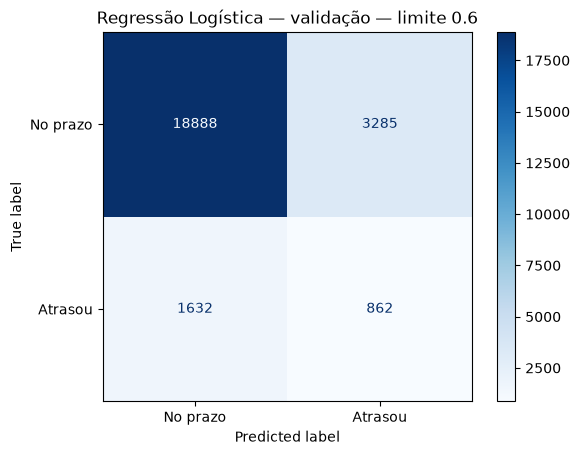

In [6]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

limite_provisorio = 0.6
previsoes_validacao = (scores_log >= limite_provisorio).astype(int)

ConfusionMatrixDisplay.from_predictions(
    y_validacao,
    previsoes_validacao,
    display_labels=["No prazo", "Atrasou"],
    cmap="Blues",
    values_format="d"
)

plt.title("Regressão Logística — validação — limite 0.6")
plt.show()

## 4. HistGradientBoosting — treino e validação

In [7]:
from sklearn.ensemble import HistGradientBoostingClassifier

modelo_hgb = HistGradientBoostingClassifier(
    max_iter=200,
    learning_rate=0.05,
    max_leaf_nodes=31,
    l2_regularization=1.0,
    class_weight="balanced",
    early_stopping=False,
    random_state=42
)

modelo_hgb.fit(X_treino, y_treino)
print("HGB treinado.")

HGB treinado.


In [8]:
previsoes_hgb = modelo_hgb.predict(X_validacao)
scores_hgb = modelo_hgb.predict_proba(X_validacao)[:, 1]

print(f"Accuracy: {accuracy_score(y_validacao, previsoes_hgb):.2%}")
print(f"Precision: {precision_score(y_validacao, previsoes_hgb, zero_division=0):.2%}")
print(f"Recall: {recall_score(y_validacao, previsoes_hgb, zero_division=0):.2%}")
print(f"F1: {f1_score(y_validacao, previsoes_hgb, zero_division=0):.2%}")
print(f"Average Precision: {average_precision_score(y_validacao, scores_hgb):.4f}")

Accuracy: 72.92%
Precision: 14.92%
Recall: 35.69%
F1: 21.04%
Average Precision: 0.1529


## 5. Rede neural — treino e validação

O balanceamento ocorre na função de perda do treino; validação e teste mantêm suas proporções reais.

In [9]:
import numpy as np
import torch
from torch import nn

# Tensores são o formato de dados utilizado pelo PyTorch.
X_treino_tensor = torch.tensor(np.asarray(X_treino), dtype=torch.float32)
y_treino_tensor = torch.tensor(np.asarray(y_treino), dtype=torch.float32)

X_validacao_tensor = torch.tensor(np.asarray(X_validacao), dtype=torch.float32)
y_validacao_tensor = torch.tensor(np.asarray(y_validacao), dtype=torch.float32)

print("PyTorch:", torch.__version__)
print("Treino:", X_treino_tensor.shape, y_treino_tensor.shape)
print("Validação:", X_validacao_tensor.shape, y_validacao_tensor.shape)

PyTorch: 2.15.0+cpu
Treino: torch.Size([41173, 159]) torch.Size([41173])
Validação: torch.Size([24667, 159]) torch.Size([24667])


In [10]:
from torch import nn

torch.manual_seed(7)

modelo_rede = nn.Sequential(
    nn.Linear(X_treino_tensor.shape[1], 128),
    nn.ReLU(),
    nn.Dropout(0.1),
    nn.Linear(128, 64),
    nn.ReLU(),
    nn.Linear(64, 1)
)

print(modelo_rede)

Sequential(
  (0): Linear(in_features=159, out_features=128, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.1, inplace=False)
  (3): Linear(in_features=128, out_features=64, bias=True)
  (4): ReLU()
  (5): Linear(in_features=64, out_features=1, bias=True)
)


In [11]:
# Calculamos o desbalanceamento usando somente o treino.
quantidade_atrasos = (y_treino_tensor == 1).sum()
quantidade_pontuais = (y_treino_tensor == 0).sum()
peso_atraso = quantidade_pontuais / quantidade_atrasos

criterio = nn.BCEWithLogitsLoss(
    pos_weight=peso_atraso.reshape(1)
)

otimizador = torch.optim.AdamW(
    modelo_rede.parameters(),
    lr=0.0003,
    weight_decay=0.01
)

print(f"Peso dos atrasos: {peso_atraso.item():.2f}")

Peso dos atrasos: 22.33


In [12]:
import pandas as pd
from copy import deepcopy
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import average_precision_score

torch.manual_seed(7)

dataset_treino = TensorDataset(X_treino_tensor, y_treino_tensor)

lotes_treino = DataLoader(
    dataset_treino,
    batch_size=256,
    shuffle=True,
    generator=torch.Generator().manual_seed(7)
)

In [13]:
historico_rede = []
melhor_quantidade = -1
tamanho_fila = int(len(y_validacao_tensor) * 0.10)

paciencia = 50
epocas_sem_melhora = 0

for epoca in range(1, 151):
    # Aprendizado: somente dados de treino.
    modelo_rede.train()
    soma_erros = 0.0

    for entradas, alvos in lotes_treino:
        otimizador.zero_grad()

        saidas = modelo_rede(entradas).squeeze(1)
        erro = criterio(saidas, alvos)

        erro.backward()
        otimizador.step()

        soma_erros += erro.item() * len(entradas)

    erro_medio = soma_erros / len(dataset_treino)

    # Validação: calcula resultados sem ajustar os parâmetros.
    modelo_rede.eval()
    with torch.no_grad():
        saidas_validacao = modelo_rede(X_validacao_tensor).squeeze(1)
        scores = torch.sigmoid(saidas_validacao).numpy()

    avaliacao = pd.DataFrame({
        "atrasou": y_validacao_tensor.numpy(),
        "score": scores
    })

    fila = avaliacao.nlargest(tamanho_fila, "score")
    encontrados = int(fila["atrasou"].sum())
    ap = average_precision_score(avaliacao["atrasou"], scores)

    historico_rede.append({
        "epoca": epoca,
        "erro_treino": erro_medio,
        "average_precision": ap,
        "atrasos_top10": encontrados
    })

    # Guarda a melhor versão e acompanha épocas sem melhoria.
    if encontrados > melhor_quantidade:
        melhor_quantidade = encontrados
        melhor_epoca = epoca
        melhor_estado = deepcopy(modelo_rede.state_dict())
        scores_rede = scores.copy()
        epocas_sem_melhora = 0
    else:
        epocas_sem_melhora += 1

    print(
        f"Época {epoca:02d} | Erro: {erro_medio:.4f} | "
        f"AP: {ap:.4f} | Atrasos na fila: {encontrados}"
    )

    if epocas_sem_melhora >= paciencia:
        print(f"\nParada antecipada na época {epoca}.")
        break

# Recupera os parâmetros da melhor época.
modelo_rede.load_state_dict(melhor_estado)
modelo_rede.eval()

print(f"\nMelhor época: {melhor_epoca}")
print(f"Atrasos encontrados: {melhor_quantidade} em {tamanho_fila} pedidos")

Época 01 | Erro: 1.3059 | AP: 0.1668 | Atrasos na fila: 465


Época 02 | Erro: 1.2396 | AP: 0.1847 | Atrasos na fila: 537


Época 03 | Erro: 1.1981 | AP: 0.1949 | Atrasos na fila: 591


Época 04 | Erro: 1.1806 | AP: 0.2014 | Atrasos na fila: 625


Época 05 | Erro: 1.1694 | AP: 0.1939 | Atrasos na fila: 577


Época 06 | Erro: 1.1557 | AP: 0.1933 | Atrasos na fila: 582


... (44 outputs left out)

Época 51 | Erro: 0.8705 | AP: 0.1416 | Atrasos na fila: 424


Época 52 | Erro: 0.8644 | AP: 0.1376 | Atrasos na fila: 427


Época 53 | Erro: 0.8675 | AP: 0.1392 | Atrasos na fila: 430


Época 54 | Erro: 0.8746 | AP: 0.1406 | Atrasos na fila: 429

Parada antecipada na época 54.

Melhor época: 4
Atrasos encontrados: 625 em 2466 pedidos


### 5.1 Avaliar e conferir a melhor época

In [14]:
import pandas as pd
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    average_precision_score
)

avaliacao_rede = pd.DataFrame({
    "atrasou": y_validacao_tensor.numpy().astype(int),
    "score": scores_rede
})

# Marca os 10% dos pedidos com maior score.
quantidade = int(len(avaliacao_rede) * 0.10)
indices = avaliacao_rede.nlargest(quantidade, "score").index

avaliacao_rede["prioridade"] = 0
avaliacao_rede.loc[indices, "prioridade"] = 1

real = avaliacao_rede["atrasou"]
alertas = avaliacao_rede["prioridade"]

print(f"Precision: {precision_score(real, alertas):.2%}")
print(f"Recall: {recall_score(real, alertas):.2%}")
print(f"F1: {f1_score(real, alertas):.2%}")
print(f"AP: {average_precision_score(real, scores_rede):.4f}")

Precision: 25.34%
Recall: 25.06%
F1: 25.20%
AP: 0.2014


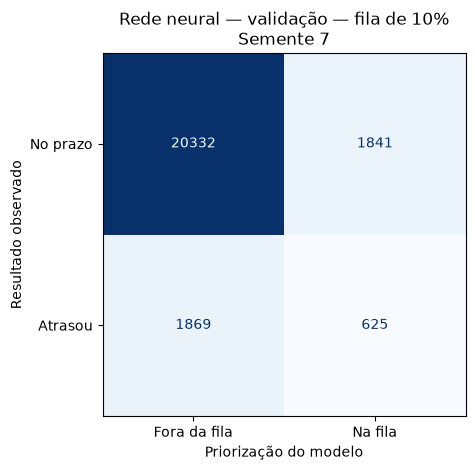

In [15]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

grafico = ConfusionMatrixDisplay.from_predictions(
    real,
    alertas,
    labels=[0, 1],
    display_labels=["No prazo", "Atrasou"],
    cmap="Blues",
    colorbar=False,
    values_format="d"
)

grafico.ax_.set_xticklabels(["Fora da fila", "Na fila"])
grafico.ax_.set_xlabel("Priorização do modelo")
grafico.ax_.set_ylabel("Resultado observado")
grafico.ax_.set_title(
    "Rede neural — validação — fila de 10%\nSemente 7"
)

plt.tight_layout()
plt.show()

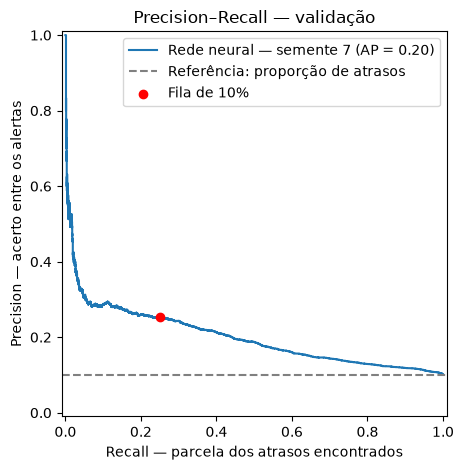

In [16]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    PrecisionRecallDisplay, precision_score, recall_score
)

real = avaliacao_rede["atrasou"]
alertas = avaliacao_rede["prioridade"]

curva = PrecisionRecallDisplay.from_predictions(
    real,
    avaliacao_rede["score"],
    name="Rede neural — semente 7"
)

curva.ax_.axhline(
    real.mean(),
    color="gray",
    linestyle="--",
    label="Referência: proporção de atrasos"
)

curva.ax_.scatter(
    recall_score(real, alertas),
    precision_score(real, alertas),
    color="red",
    label="Fila de 10%",
    zorder=3
)

curva.ax_.set_xlabel("Recall — parcela dos atrasos encontrados")
curva.ax_.set_ylabel("Precision — acerto entre os alertas")
curva.ax_.set_title("Precision–Recall — validação")
curva.ax_.legend()

plt.tight_layout()
plt.show()

In [17]:
import numpy as np

modelo_rede.eval()

with torch.no_grad():
    scores_conferencia = torch.sigmoid(
        modelo_rede(X_validacao_tensor).squeeze(1)
    ).numpy()

np.testing.assert_allclose(
    scores_conferencia,
    avaliacao_rede["score"].to_numpy(),
    rtol=1e-5,
    atol=1e-7
)

print("Modelo corresponde aos resultados apresentados.")

Modelo corresponde aos resultados apresentados.


## 6. Comparar os modelos na validação

A fila é a parcela de pedidos com maiores scores. Os pedidos fora dela não são necessariamente pontuais.

In [18]:
resultados_fila = []

for nome, scores in {"Logística": scores_log, "HGB": scores_hgb, "Rede neural": scores_rede}.items():
    avaliacao = pd.DataFrame({
        "atrasou": y_validacao,
        "score": scores
    })

    for percentual in [5, 10, 20]:
        quantidade = int(len(avaliacao) * percentual / 100)
        selecionados = avaliacao.nlargest(quantidade, "score")
        atrasos = int(selecionados["atrasou"].sum())

        resultados_fila.append({
            "modelo": nome,
            "revisao_%": percentual,
            "pedidos_revisados": quantidade,
            "atrasos_encontrados": atrasos,
            "precision_%": 100 * atrasos / quantidade,
            "recall_%": 100 * atrasos / avaliacao["atrasou"].sum()
        })

pd.DataFrame(resultados_fila).round(2)

,modelo,revisao_%,pedidos_revisados,atrasos_encontrados,precision_%,recall_%
0,Logística,5,1233,307,24.90,12.31
1,Logística,10,2466,569,23.07,22.81
2,Logística,20,4933,956,19.38,38.33
3,HGB,5,1233,254,20.60,10.18
4,HGB,10,2466,438,17.76,17.56
5,HGB,20,4933,763,15.47,30.59
6,Rede neural,5,1233,344,27.90,13.79
7,Rede neural,10,2466,625,25.34,25.06
8,Rede neural,20,4933,1031,20.90,41.34


## 7. Avaliação final no teste

As configurações e a regra de fila já estão fixadas. As próximas células apenas aplicam os modelos treinados; não escolhem hiperparâmetros nem substituem automaticamente o modelo do site pelo vencedor.

O teste já foi consultado em estudos anteriores. Reexecutá-lo não cria uma avaliação inédita; não use estes resultados para continuar ajustando os modelos. A comparação abaixo é recalculada nesta rodada, sem tabela histórica fixa.


In [19]:
# Reutiliza a logística treinada acima, sem novo ajuste.
scores_log_teste = modelo_logistico.predict_proba(dados["X"]["teste"])[:, 1]

In [20]:
import pandas as pd
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    average_precision_score, confusion_matrix
)

avaliacao_log_teste = pd.DataFrame({
    "atrasou": dados["y"]["teste"],
    "score": scores_log_teste
})

quantidade_log = int(len(avaliacao_log_teste) * 0.10)
indices_log = avaliacao_log_teste.nlargest(
    quantidade_log, "score"
).index

avaliacao_log_teste["prioridade"] = 0
avaliacao_log_teste.loc[indices_log, "prioridade"] = 1

real_log = avaliacao_log_teste["atrasou"]
alertas_log = avaliacao_log_teste["prioridade"]

print(f"Pedidos avaliados: {len(avaliacao_log_teste)}")
print(f"Pedidos na fila: {quantidade_log}")
print(f"Atrasos encontrados: {int(real_log[alertas_log == 1].sum())}")
print(f"Precision: {precision_score(real_log, alertas_log):.2%}")
print(f"Recall: {recall_score(real_log, alertas_log):.2%}")
print(f"F1: {f1_score(real_log, alertas_log):.2%}")
print(f"AP: {average_precision_score(real_log, scores_log_teste):.4f}")
print("Matriz de confusão:")
print(confusion_matrix(real_log, alertas_log, labels=[0, 1]))

Pedidos avaliados: 25550
Pedidos na fila: 2555
Atrasos encontrados: 275
Precision: 10.76%
Recall: 24.47%
F1: 14.95%
AP: 0.0884
Matriz de confusão:
[[22146  2280]
 [  849   275]]


In [21]:
from sklearn.metrics import confusion_matrix

X_teste_tensor = torch.tensor(
    np.asarray(dados["X"]["teste"]),
    dtype=torch.float32
)

modelo_rede.eval()

with torch.no_grad():
    scores_teste = torch.sigmoid(
        modelo_rede(X_teste_tensor).squeeze(1)
    ).numpy()

avaliacao_teste = pd.DataFrame({
    "atrasou": np.asarray(dados["y"]["teste"]),
    "score": scores_teste
})

quantidade_teste = int(len(avaliacao_teste) * 0.10)
indices = avaliacao_teste.nlargest(quantidade_teste, "score").index

avaliacao_teste["prioridade"] = 0
avaliacao_teste.loc[indices, "prioridade"] = 1

real_teste = avaliacao_teste["atrasou"]
alertas_teste = avaliacao_teste["prioridade"]

print(f"Pedidos avaliados: {len(avaliacao_teste)}")
print(f"Pedidos na fila: {quantidade_teste}")
print(f"Frequência de atraso: {real_teste.mean():.2%}")
print(f"Precision: {precision_score(real_teste, alertas_teste):.2%}")
print(f"Recall: {recall_score(real_teste, alertas_teste):.2%}")
print(f"F1: {f1_score(real_teste, alertas_teste):.2%}")
print(f"AP: {average_precision_score(real_teste, scores_teste):.4f}")
print("Matriz de confusão:")
print(confusion_matrix(real_teste, alertas_teste, labels=[0, 1]))

Pedidos avaliados: 25550
Pedidos na fila: 2555
Frequência de atraso: 4.40%
Precision: 11.66%
Recall: 26.51%
F1: 16.20%


AP: 0.0981
Matriz de confusão:
[[22169  2257]
 [  826   298]]


In [22]:
# Acrescenta o HGB à mesma avaliação, sem ajustar o modelo no teste.
scores_hgb_teste = modelo_hgb.predict_proba(dados["X"]["teste"])[:, 1]
resultados_teste = []
alvos_teste = np.asarray(dados["y"]["teste"]).ravel()
quantidade_fila_teste = int(len(alvos_teste) * 0.10)

for nome, scores in {
    "Logística": scores_log_teste,
    "HGB": scores_hgb_teste,
    "Rede neural": scores_teste,
}.items():
    # Mesmo desempate e mesma capacidade de revisão para os três modelos.
    selecionados = pd.Series(scores).nlargest(quantidade_fila_teste).index
    alertas = np.zeros(len(alvos_teste), dtype=int)
    alertas[selecionados] = 1
    tn, fp, fn, tp = confusion_matrix(alvos_teste, alertas, labels=[0, 1]).ravel()
    resultados_teste.append({
        "modelo": nome,
        "pedidos": len(alvos_teste),
        "na_fila": int(alertas.sum()),
        "atrasos_encontrados": int(tp),
        "falsos_positivos": int(fp),
        "falsos_negativos": int(fn),
        "accuracy_%": 100 * accuracy_score(alvos_teste, alertas),
        "precision_%": 100 * precision_score(alvos_teste, alertas, zero_division=0),
        "recall_%": 100 * recall_score(alvos_teste, alertas, zero_division=0),
        "f1_%": 100 * f1_score(alvos_teste, alertas, zero_division=0),
        "AP": average_precision_score(alvos_teste, scores),
    })

comparacao_teste = pd.DataFrame(resultados_teste)
print(f"Frequência real de atrasos no teste: {alvos_teste.mean():.2%}")
display(comparacao_teste.round(4))

Frequência real de atrasos no teste: 4.40%


,modelo,pedidos,na_fila,atrasos_encontrados,falsos_positivos,falsos_negativos,accuracy_%,precision_%,recall_%,f1_%,AP
0,Logística,25550,2555,275,2280,849,87.7534,10.7632,24.4662,14.9497,0.0884
1,HGB,25550,2555,279,2276,845,87.7847,10.9198,24.8221,15.1672,0.0858
2,Rede neural,25550,2555,298,2257,826,87.9335,11.6634,26.5125,16.2001,0.0981


## 8. Salvar e recarregar a rede e o pré-processamento

A partir daqui, o par de arquivos da aplicação é atualizado. A conferência exige os mesmos scores da melhor época avaliada.

In [23]:
import joblib
import torch
import sklearn

pasta_modelos = raiz / "Modelos"

# Coloca a rede em modo de previsão.
modelo_rede.eval()

# Salva os pesos aprendidos pela rede.
torch.save(
    modelo_rede.state_dict(),
    pasta_modelos / "rede_neural.pt"
)

# Guarda o tratamento aprendido no treino e as configurações.
pacote_inferencia = {
    "preprocessador": dados["preprocessador"],
    "colunas_entrada": dados["colunas_entrada"],
    "nomes_atributos": dados["nomes_atributos"],
    "numero_entradas": modelo_rede[0].in_features,
    "camadas_ocultas": [
        modelo_rede[0].out_features,
        modelo_rede[3].out_features
    ],
    "dropout": modelo_rede[2].p,
    "semente": 7,
    "melhor_epoca": int(melhor_epoca),
    "fracao_fila": 0.10,
    "versao_torch": str(torch.__version__),
    "versao_sklearn": sklearn.__version__
}

joblib.dump(
    pacote_inferencia,
    pasta_modelos / "preprocessador_rede.joblib"
)

print("Arquivos salvos em:", pasta_modelos.relative_to(raiz))

Arquivos salvos em: Modelos


In [24]:
import numpy as np
import joblib
import torch
from torch import nn

# 1. Carrega as configurações e o pré-processamento.
pacote_carregado = joblib.load(
    pasta_modelos / "preprocessador_rede.joblib"
)

camada1, camada2 = pacote_carregado["camadas_ocultas"]

# 2. Reconstrói a estrutura da rede.
rede_carregada = nn.Sequential(
    nn.Linear(pacote_carregado["numero_entradas"], camada1),
    nn.ReLU(),
    nn.Dropout(pacote_carregado["dropout"]),
    nn.Linear(camada1, camada2),
    nn.ReLU(),
    nn.Linear(camada2, 1)
)

# 3. Recupera os pesos aprendidos.
pesos = torch.load(
    pasta_modelos / "rede_neural.pt",
    map_location="cpu",
    weights_only=True
)

rede_carregada.load_state_dict(pesos)
rede_carregada.eval()

# 4. Calcula novamente os scores da validação.
entradas = torch.tensor(
    dados["X"]["validacao"],
    dtype=torch.float32
)

with torch.no_grad():
    scores_recarregados = torch.sigmoid(
        rede_carregada(entradas).squeeze(1)
    ).numpy()

# 5. Compara com os scores que vocês já avaliaram.
np.testing.assert_allclose(
    
    scores_recarregados,
    avaliacao_rede["score"].to_numpy(),
    rtol=1e-5,
    atol=1e-7
)

print("Verificação aprovada: a rede salva reproduz os scores!")

Verificação aprovada: a rede salva reproduz os scores!


## 9. Reproduzir o tratamento a partir do CSV consolidado

In [25]:
import sys
import pandas as pd
import numpy as np
import torch

if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

from src.tratar_dados_ml import corrigir_distancias, limpar_atributos

# 1. Lê o consolidado, antes do preenchimento dos valores ausentes.
base = pd.read_csv(
    caminho_consolidado,
    dtype={"customer_zip_code_prefix": "string"}
)

assert base["order_id"].is_unique, "Consolidado com pedidos duplicados."

# Seleciona os mesmos pedidos da validação, na mesma ordem.
ids = dados["metadados"]["validacao"]["order_id"].tolist()

base = (
    base.set_index("order_id")
    .loc[ids]
    .reset_index()
)

# 2. Aplica as mesmas regras de distância e limpeza.
base = corrigir_distancias(
    base,
    raiz / "Dados" / "Brazilian Logistic",
    registro=[]
)

base = base.set_index("order_id").loc[ids].reset_index()
atributos, _ = limpar_atributos(base)

# 3. Aplica o pré-processador que já foi ajustado no treino.
matriz = pacote_carregado["preprocessador"].transform(
    atributos[pacote_carregado["colunas_entrada"]]
).astype(np.float32)

# Confere se o tratamento reproduziu a matriz original.
np.testing.assert_allclose(
    matriz,
    dados["X"]["validacao"],
    rtol=1e-5,
    atol=1e-7
)

# 4. Executa a rede carregada e confere os scores.
rede_carregada.eval()

with torch.no_grad():
    scores_desde_csv = torch.sigmoid(
        rede_carregada(torch.from_numpy(matriz)).squeeze(1)
    ).numpy()

np.testing.assert_allclose(
    scores_desde_csv,
    avaliacao_rede["score"].to_numpy(),
    rtol=1e-5,
    atol=1e-7
)

print("Conferência aprovada: tratamento e scores reproduzidos!")

Conferência aprovada: tratamento e scores reproduzidos!


## 10. Conferir a inferência e a fila

Primeiro vemos as funções didaticamente; depois comparamos com as funções do módulo usado pela aplicação.

In [26]:
def prever_pedidos(pedidos, pacote, modelo):
    """Recebe pedidos consolidados com distâncias já corrigidas."""

    # Limpa e transforma os atributos.
    atributos, _ = limpar_atributos(pedidos)

    matriz = pacote["preprocessador"].transform(
        atributos[pacote["colunas_entrada"]]
    ).astype(np.float32)

    # Calcula os scores usando a rede treinada.
    modelo.eval()

    with torch.no_grad():
        scores = torch.sigmoid(
            modelo(torch.from_numpy(matriz)).squeeze(1)
        ).numpy()

    resultado = pedidos[["order_id"]].copy()
    resultado["score_atraso"] = scores

    return resultado


# Usa os pedidos preparados na conferência anterior.
previsoes = prever_pedidos(base, pacote_carregado, rede_carregada)

# Confere se a função preservou os resultados.
np.testing.assert_allclose(
    previsoes["score_atraso"].to_numpy(),
    scores_desde_csv,
    rtol=1e-5,
    atol=1e-7
)

print("Função de inferência conferida!")
display(previsoes.head())

Função de inferência conferida!


,order_id,score_atraso
0,35153d02b70cad4eb36cc178280458ed,0.360837
1,4f6daad34df49e10c8072b33faafcb2a,0.681043
2,0462bad26ccfb8508951beb9ea398ae1,0.338295
3,fbe41a4974e4a492e085d90e5be0b3e3,0.292250
4,20ddbb26c9b5f5acad69796272489c0a,0.447972


In [27]:
def priorizar_pedidos(previsoes, fracao):
    resultado = previsoes.copy().reset_index(drop=True)

    quantidade = int(len(resultado) * fracao)
    selecionados = resultado.nlargest(
        quantidade, "score_atraso"
    ).index

    resultado["prioridade"] = 0
    resultado.loc[selecionados, "prioridade"] = 1

    return resultado


previsoes_priorizadas = priorizar_pedidos(
    previsoes,
    pacote_carregado["fracao_fila"]
)

# Confere se reproduz a seleção já avaliada na validação.
np.testing.assert_array_equal(
    previsoes_priorizadas["prioridade"].to_numpy(),
    avaliacao_rede["prioridade"].to_numpy()
)

# Organiza a fila do maior para o menor score.
fila = (
    previsoes_priorizadas[
        previsoes_priorizadas["prioridade"] == 1
    ]
    .sort_values("score_atraso", ascending=False, kind="stable")
    .reset_index(drop=True)
)

print("Priorização conferida!")
print(f"Pedidos avaliados: {len(previsoes_priorizadas)}")
print(f"Pedidos na fila: {len(fila)}")

display(fila.head(10))

Priorização conferida!
Pedidos avaliados: 24667
Pedidos na fila: 2466


,order_id,score_atraso,prioridade
0,f7923db0430587601c2aef15ec4b8af4,0.993698,1
1,0a93b40850d3f4becf2f276666e01340,0.992448,1
2,daed0f3aefd193de33c31e21b16a3b3a,0.959722,1
3,9eac94dce77597b831e8c0dfc584bc8b,0.931162,1
4,cb560d710377eef2c41351f25c732da1,0.916262,1
5,e7d3f9457c859cd5b63a25a4c2afb2e0,0.902666,1
6,984d353f61e2dc775d7dd4b09882b481,0.898564,1
7,b9f64aec40db08ee03b99891f3bab687,0.896504,1
8,cfed507ac357129f750f05a0d7d71b15,0.895338,1
9,14ef2221cc3570aa6ce512fc353529b3,0.894307,1


In [28]:
from src.inferencia import prever_pedidos, priorizar_pedidos

resultado_modulo = prever_pedidos(
    base, pacote_carregado, rede_carregada
)

resultado_modulo = priorizar_pedidos(
    resultado_modulo,
    pacote_carregado["fracao_fila"]
)

np.testing.assert_allclose(
    resultado_modulo["score_atraso"],
    previsoes_priorizadas["score_atraso"],
    rtol=1e-5,
    atol=1e-7
)

np.testing.assert_array_equal(
    resultado_modulo["prioridade"],
    previsoes_priorizadas["prioridade"]
)

print("Módulo conferido: mesmos scores e mesma fila!")

Módulo conferido: mesmos scores e mesma fila!


## 11. Gerar os CSV de demonstração e conferir o módulo

O próprio notebook executa `python -m src.inferencia` com o Python do kernel e a raiz correta. Não é necessário abrir outro terminal.

In [29]:
# Seleciona o identificador e os atributos utilizados pelo modelo.
colunas_demo = ["order_id"] + pacote_carregado["colunas_entrada"]

# A variável base já possui as distâncias corrigidas.
entrada_demo = base[colunas_demo].copy()

caminho_demo = raiz / "Dados" / "pedidos_demo_validacao.csv"

entrada_demo.to_csv(caminho_demo, index=False)

print("Arquivo salvo em:", caminho_demo.relative_to(raiz))
print("Pedidos:", len(entrada_demo))
print("Colunas:", len(entrada_demo.columns))

Arquivo salvo em: Dados\pedidos_demo_validacao.csv
Pedidos: 24667
Colunas: 30


In [30]:
import os
import subprocess

# UTF-8 evita diferenças de acentuação entre o kernel e o terminal do Windows.
ambiente_inferencia = os.environ.copy()
ambiente_inferencia["PYTHONIOENCODING"] = "utf-8"
execucao = subprocess.run(
    [sys.executable, "-m", "src.inferencia"],
    cwd=raiz,
    env=ambiente_inferencia,
    capture_output=True,
    text=True,
    encoding="utf-8",
)
print(execucao.stdout)
if execucao.stderr:
    print(execucao.stderr)
execucao.check_returncode()

Previsão e priorização executadas!
Pedidos avaliados: 24667
Pedidos na fila: 2466
Resultado salvo em: C:\Users\ghost\OneDrive\Documentos\ChatGPT\Nikolas\BootcampTCS\EntregaCertaAI_Pontos\validacao_notebooks_sequenciais\Dados\previsoes_demo_validacao.csv



In [31]:
import pandas as pd
import numpy as np

resultado_terminal = pd.read_csv(
    raiz / "Dados" / "previsoes_demo_validacao.csv",
    dtype={"order_id": "string"}
)

# Alinha os resultados pelo identificador e verifica duplicatas.
resultado_terminal = resultado_terminal.set_index(
    "order_id"
).sort_index()

referencia_notebook = previsoes_priorizadas.set_index(
    "order_id"
).sort_index()

assert resultado_terminal.index.is_unique
assert referencia_notebook.index.is_unique

# Confere se são exatamente os mesmos pedidos.
np.testing.assert_array_equal(
    resultado_terminal.index.to_numpy(),
    referencia_notebook.index.to_numpy()
)

# Compara os scores, permitindo pequenas diferenças numéricas.
np.testing.assert_allclose(
    resultado_terminal["score_atraso"],
    referencia_notebook["score_atraso"],
    rtol=1e-5,
    atol=1e-7
)

# A seleção da fila precisa ser exatamente igual.
np.testing.assert_array_equal(
    resultado_terminal["prioridade"],
    referencia_notebook["prioridade"]
)

print("Conferência final aprovada: mesmos pedidos, scores e prioridades!")

Conferência final aprovada: mesmos pedidos, scores e prioridades!


## Conclusão da execução

Se a última conferência foi aprovada, o treino, o par salvo e a inferência reproduziram os mesmos pedidos, scores e prioridades. Isso comprova a integração; a qualidade preditiva é a mostrada nas métricas, não a mensagem de aprovação.

Salve o notebook com suas saídas para o artigo. Continue na etapa de PostgreSQL do [guia de instalação](../Docs/instalacao_novo_pc.md). Não é necessário executar os notebooks de experimentos para iniciar o site.
